In [6]:
# STEP 1: IMPORT LIBRARIES & CREATE DIMENSION TABLES

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from datetime import datetime, timedelta

# Set consistent seed and styling
np.random.seed(42)
sns.set_theme(style="whitegrid")

# 1. Dim_Content (Catalog Metadata)
n_contents = 15
genres = ['Sci-Fi', 'Thriller', 'Drama', 'Comedy', 'Action']

content_df = pd.DataFrame({
    'content_id': range(1, n_contents + 1),
    'title': [f"Series_{chr(65 + i)}" for i in range(n_contents)],
    'genre': np.random.choice(genres, n_contents),
    'total_episodes': np.random.choice([6, 8, 10], n_contents)
})

# 2. Dim_User (Subscribers)
n_users = 1000
signup_dates = [datetime(2025, 1, 1) + timedelta(days=int(d)) for d in np.random.randint(0, 180, n_users)]

user_df = pd.DataFrame({
    'user_id': range(101, 101 + n_users),
    'signup_date': signup_dates,
    'plan_tier': np.random.choice(['Standard', 'Premium', 'Basic'], n_users, p=[0.5, 0.3, 0.2])
})

# Verification
print("=== Step 1 Completed ===")
print(f"Content Catalog: {content_df.shape[0]} titles loaded.")
print(f"User Base: {user_df.shape[0]} subscribers created.\n")
print(content_df.head(3))
print("\n", user_df.head(3))

=== Step 1 Completed ===
Content Catalog: 15 titles loaded.
User Base: 1000 subscribers created.

   content_id     title   genre  total_episodes
0           1  Series_A  Comedy               8
1           2  Series_B  Action               8
2           3  Series_C   Drama               8

    user_id signup_date plan_tier
0      101  2025-06-24     Basic
1      102  2025-02-20   Premium
2      103  2025-04-18   Premium


In [9]:

# STEP 2: SIMULATE FACT_STREAM & CHURN LOGS

streams = []
churn_records = {}

for u_id, signup in zip(user_df['user_id'], user_df['signup_date']):
    # Each user starts watching 1 to 2 series
    watched_series = content_df.sample(np.random.randint(1, 3))
    last_watch_time = signup + timedelta(days=np.random.randint(1, 5))
    finished_binge = False

    for _, series in watched_series.iterrows():
        # Viewing pace: lower number = faster binger (hours between sessions)
        pace_hours = np.random.exponential(scale=18)
        ep_completed = 0

        for ep in range(1, series['total_episodes'] + 1):
            session_start = last_watch_time + timedelta(
                hours=pace_hours * (ep - 1) + np.random.uniform(0.5, 4)
            )
            session_end = session_start + timedelta(minutes=np.random.randint(40, 55))

            streams.append({
                'user_id': u_id,
                'content_id': series['content_id'],
                'ep_number': ep,
                'session_start': session_start,
                'session_end': session_end,
                'is_completed': True
            })
            ep_completed = ep
            last_watch_time = session_end

            # ~12% chance to abandon the show mid-season
            if np.random.rand() > 0.88:
                break

        # Check if the user completed the finale
        if ep_completed == series['total_episodes']:
            finished_binge = True

    # Business logic: Post-binge finishers face higher 14-day cancellation hazard
    if finished_binge and np.random.rand() < 0.35:
        churn_records[u_id] = (1, last_watch_time + timedelta(days=np.random.randint(2, 14)))
    elif np.random.rand() < 0.15:
        churn_records[u_id] = (1, last_watch_time + timedelta(days=np.random.randint(20, 60)))
    else:
        churn_records[u_id] = (0, None)

# Build Fact DataFrame and enrich Dim_User with churn flags
stream_df = pd.DataFrame(streams)
user_df['churn_status'] = user_df['user_id'].map(lambda x: churn_records[x][0])
user_df['churn_date'] = user_df['user_id'].map(lambda x: churn_records[x][1])

# Verification
print("=== Step 2 Completed ===")
print(f"Total Stream Sessions Logged: {len(stream_df):,}")
print(f"Overall Platform Churn Rate: {user_df['churn_status'].mean() * 100:.2f}%\n")
print(stream_df.head(4))

=== Step 2 Completed ===
Total Stream Sessions Logged: 7,810
Overall Platform Churn Rate: 31.40%

   user_id  content_id  ep_number              session_start  \
0      101           1          1 2025-06-28 01:15:11.543587   
1      101           1          2 2025-06-28 18:29:02.459476   
2      101           1          3 2025-06-30 02:39:56.627061   
3      101           1          4 2025-07-01 22:11:51.604182   

                 session_end  is_completed  
0 2025-06-28 01:59:11.543587          True  
1 2025-06-28 19:13:02.459476          True  
2 2025-06-30 03:22:56.627061          True  
3 2025-07-01 23:01:51.604182          True  


In [10]:

# STEP 3: FEATURE ENGINEERING (VELOCITY & DTC)


# 1. Join stream logs with content metadata and user details
df = stream_df.merge(content_df, on='content_id').merge(user_df, on='user_id')

# 2. Aggregate metrics per user per series
agg_series = df.groupby(
    ['user_id', 'content_id', 'title', 'genre', 'total_episodes', 'plan_tier', 'churn_status']
).agg(
    episodes_watched=('ep_number', 'count'),
    first_session=('session_start', 'min'),
    last_session=('session_end', 'max')
).reset_index()

# 3. Completion flag: Did the user reach the finale?
agg_series['is_series_complete'] = agg_series['episodes_watched'] == agg_series['total_episodes']

# 4. Days-to-Finish (DTC) in days (minimum bounded at 0.5 to prevent division by zero for single-day bingers)
agg_series['days_to_finish'] = (agg_series['last_session'] - agg_series['first_session']).dt.total_seconds() / 86400.0
agg_series['days_to_finish'] = agg_series['days_to_finish'].apply(lambda x: max(x, 0.5))

# 5. Core KPI: Binge Velocity (Episodes per Day)
agg_series['binge_velocity'] = (agg_series['episodes_watched'] / agg_series['days_to_finish']).round(2)

# 6. Filter cohort to subscribers who completed their series
df_completed = agg_series[agg_series['is_series_complete'] == True].copy()

# Verification
print("=== Step 3 Completed ===")
print(f"Total Series Started: {len(agg_series):,}")
print(f"Series Fully Completed: {len(df_completed):,} ({len(df_completed)/len(agg_series)*100:.1f}%)")
print(f"Average Binge Velocity: {df_completed['binge_velocity'].mean():.2f} episodes/day\n")
print(df_completed[['user_id', 'title', 'total_episodes', 'days_to_finish', 'binge_velocity', 'churn_status']].head(4))

=== Step 3 Completed ===
Total Series Started: 1,497
Series Fully Completed: 640 (42.8%)
Average Binge Velocity: 1.09 episodes/day

   user_id     title  total_episodes  days_to_finish  binge_velocity  \
0      101  Series_A               8       17.104031            0.47   
1      101  Series_D               6       18.146797            0.33   
2      102  Series_D               6        0.767097            7.82   
6      105  Series_L              10       33.031267            0.30   

   churn_status  
0             0  
1             0  
2             0  
6             0  


In [11]:

# STEP 4: QUANTILE SEGMENTATION & CORRELATION


# 1. Segment finished viewers into 4 consumption speed cohorts (quartiles)
df_completed['velocity_quantile'] = pd.qcut(
    df_completed['binge_velocity'],
    q=4,
    labels=['Q1 (Slowest)', 'Q2 (Moderate)', 'Q3 (Fast)', 'Q4 (Extreme Binge)']
)

# 2. Risk aggregation matrix by velocity tier
risk_summary = df_completed.groupby('velocity_quantile', observed=False).agg(
    total_viewers=('user_id', 'count'),
    avg_velocity=('binge_velocity', 'mean'),
    median_days_to_finish=('days_to_finish', 'median'),
    churned_users=('churn_status', 'sum'),
    churn_rate=('churn_status', 'mean')
).reset_index()

risk_summary['churn_rate_pct'] = (risk_summary['churn_rate'] * 100).round(2)
risk_summary['avg_velocity'] = risk_summary['avg_velocity'].round(2)
risk_summary['median_days_to_finish'] = risk_summary['median_days_to_finish'].round(1)

# 3. Pearson Correlation (Binge Velocity vs. Churn Outcome)
corr_coeff = df_completed['binge_velocity'].corr(df_completed['churn_status'])

# Print Executive Summary Table
print("=== Step 4 Completed: BINGE VELOCITY VS CHURN RISK MATRIX ===")
print(risk_summary[['velocity_quantile', 'total_viewers', 'avg_velocity', 'median_days_to_finish', 'churn_rate_pct']])
print(f"\nPearson Correlation between Binge Velocity & Churn: {corr_coeff:.3f}")

=== Step 4 Completed: BINGE VELOCITY VS CHURN RISK MATRIX ===
    velocity_quantile  total_viewers  avg_velocity  median_days_to_finish  \
0        Q1 (Slowest)            167          0.19                   41.7   
1       Q2 (Moderate)            153          0.41                   18.1   
2           Q3 (Fast)            161          0.82                    9.1   
3  Q4 (Extreme Binge)            159          2.97                    3.0   

   churn_rate_pct  
0           42.51  
1           42.48  
2           49.69  
3           47.80  

Pearson Correlation between Binge Velocity & Churn: 0.034


/tmp/ipykernel_721/3557397092.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


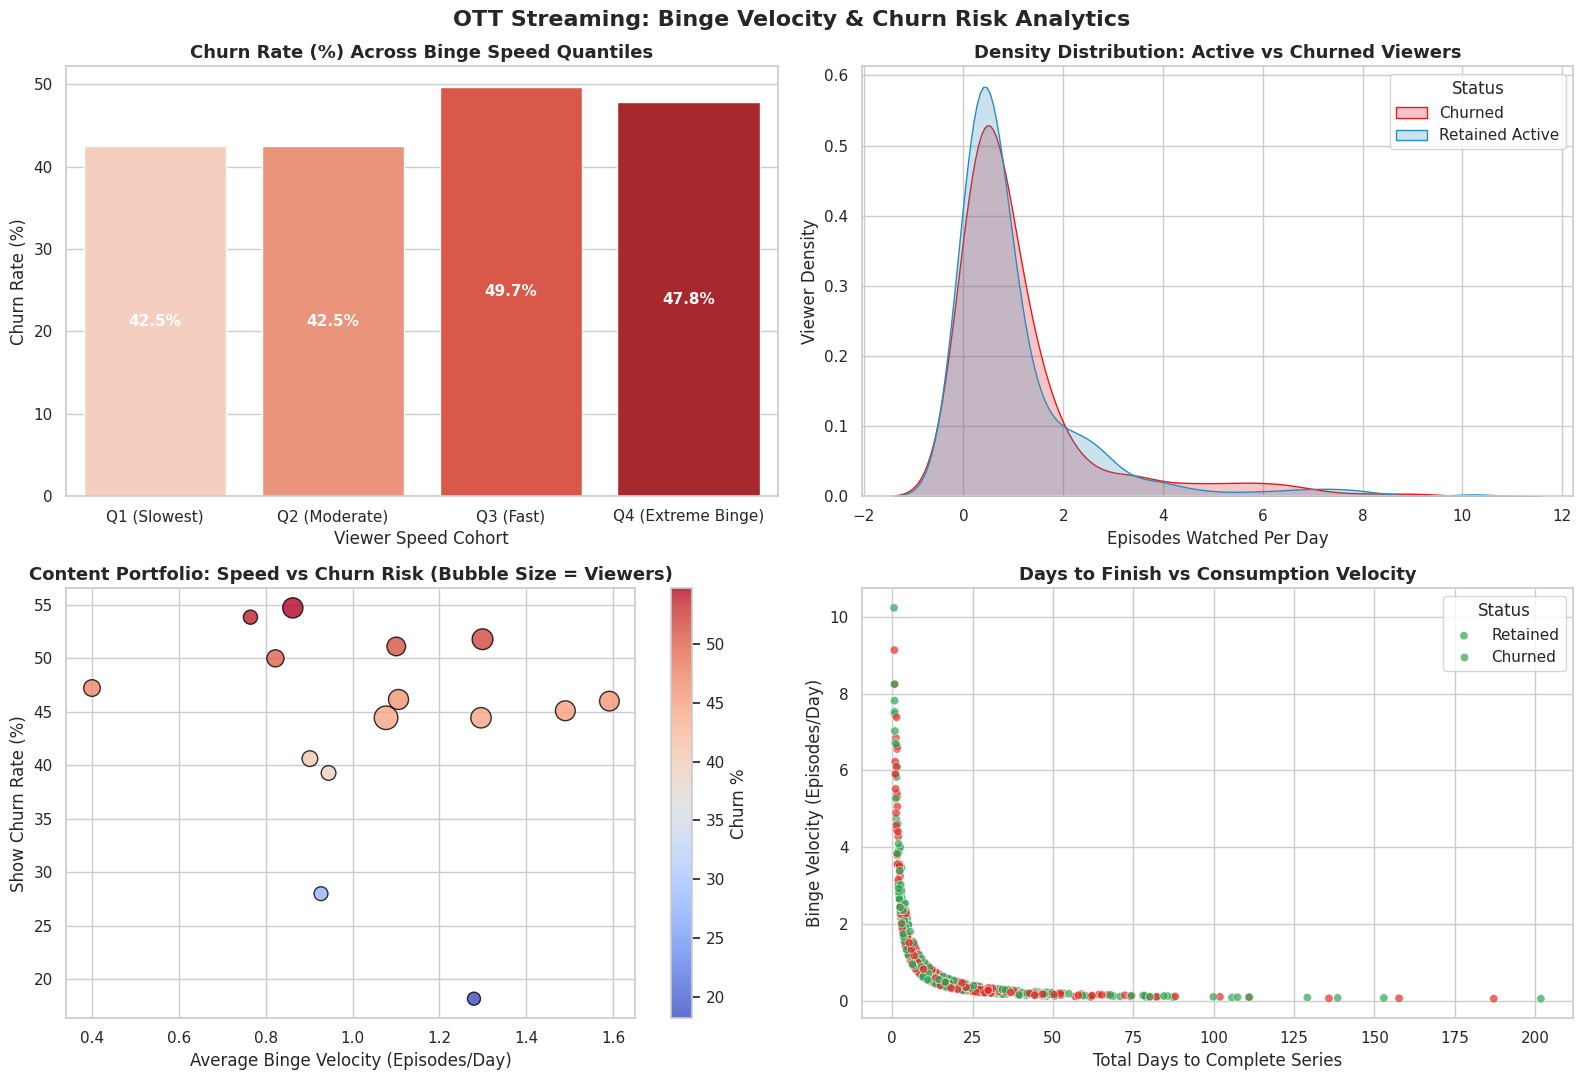

=== Step 5 Completed: Executive Visual Suite Rendered ===


In [12]:

# STEP 5: 4-PANEL EXECUTIVE VISUALIZATION


fig, axes = plt.subplots(2, 2, figsize=(16, 11))
fig.suptitle('OTT Streaming: Binge Velocity & Churn Risk Analytics', fontsize=16, weight='bold', y=0.98)

# Panel 1: Churn Rate by Velocity Quantile
sns.barplot(
    data=risk_summary,
    x='velocity_quantile',
    y='churn_rate_pct',
    palette='Reds',
    ax=axes[0, 0]
)
axes[0, 0].set_title('Churn Rate (%) Across Binge Speed Quantiles', fontsize=13, weight='bold')
axes[0, 0].set_xlabel('Viewer Speed Cohort')
axes[0, 0].set_ylabel('Churn Rate (%)')
for p in axes[0, 0].patches:
    axes[0, 0].annotate(f"{p.get_height():.1f}%",
                        (p.get_x() + p.get_width() / 2., p.get_height() / 2),
                        ha='center', va='center', color='white', weight='bold', fontsize=11)

# Panel 2: Distribution of Binge Velocity by Churn Outcome
sns.kdeplot(
    data=df_completed,
    x='binge_velocity',
    hue='churn_status',
    common_norm=False,
    fill=True,
    palette={0: '#2b8cbe', 1: '#e41a1c'},
    ax=axes[0, 1]
)
axes[0, 1].set_title('Density Distribution: Active vs Churned Viewers', fontsize=13, weight='bold')
axes[0, 1].set_xlabel('Episodes Watched Per Day')
axes[0, 1].set_ylabel('Viewer Density')
axes[0, 1].legend(['Churned', 'Retained Active'], title='Status')

# Panel 3: Content-Level Risk Matrix
content_perf = df_completed.groupby('title').agg(
    avg_velocity=('binge_velocity', 'mean'),
    churn_rate=('churn_status', 'mean'),
    total_finishers=('user_id', 'count')
).reset_index()

scatter = axes[1, 0].scatter(
    content_perf['avg_velocity'],
    content_perf['churn_rate'] * 100,
    s=content_perf['total_finishers'] * 4,
    c=content_perf['churn_rate'] * 100,
    cmap='coolwarm',
    alpha=0.8,
    edgecolor='black'
)
axes[1, 0].set_title('Content Portfolio: Speed vs Churn Risk (Bubble Size = Viewers)', fontsize=13, weight='bold')
axes[1, 0].set_xlabel('Average Binge Velocity (Episodes/Day)')
axes[1, 0].set_ylabel('Show Churn Rate (%)')
fig.colorbar(scatter, ax=axes[1, 0], label='Churn %')

# Panel 4: Days to Finish vs Binge Velocity
sns.scatterplot(
    data=df_completed,
    x='days_to_finish',
    y='binge_velocity',
    hue='churn_status',
    palette={0: '#31a354', 1: '#de2d26'},
    alpha=0.7,
    ax=axes[1, 1]
)
axes[1, 1].set_title('Days to Finish vs Consumption Velocity', fontsize=13, weight='bold')
axes[1, 1].set_xlabel('Total Days to Complete Series')
axes[1, 1].set_ylabel('Binge Velocity (Episodes/Day)')
axes[1, 1].legend(['Retained', 'Churned'], title='Status')

plt.tight_layout()
plt.show()

print("=== Step 5 Completed: Executive Visual Suite Rendered ===")

In [13]:
# ==========================================
# STEP 6: EXPORT CSV ARTIFACTS & DASHBOARD IMAGE
# ==========================================

# 1. Save the 4-panel dashboard as a high-res image
fig.savefig('ott_binge_churn_dashboard.png', dpi=300, bbox_inches='tight')
print("Saved dashboard visual: 'ott_binge_churn_dashboard.png'")

# 2. Export behavioral risk quantile summary
risk_summary.to_csv('binge_velocity_risk_quantiles.csv', index=False)
print("Saved risk quantiles: 'binge_velocity_risk_quantiles.csv'")

# 3. Export content catalog risk matrix
content_perf.to_csv('content_portfolio_churn_matrix.csv', index=False)
print("Saved content portfolio performance: 'content_portfolio_churn_matrix.csv'")

# 4. Export actionable retention intervention list (fast bingers who haven't churned yet)
retention_targets = df_completed[
    (df_completed['velocity_quantile'] == 'Q4 (Extreme Binge)') &
    (df_completed['churn_status'] == 0)
][['user_id', 'title', 'genre', 'binge_velocity', 'days_to_finish', 'last_session']]

retention_targets.to_csv('high_priority_retention_targets.csv', index=False)
print(f"Saved {len(retention_targets)} intervention targets: 'high_priority_retention_targets.csv'")

print("\n=== Project Pipeline Completed Successfully! ===")

Saved dashboard visual: 'ott_binge_churn_dashboard.png'
Saved risk quantiles: 'binge_velocity_risk_quantiles.csv'
Saved content portfolio performance: 'content_portfolio_churn_matrix.csv'
Saved 83 intervention targets: 'high_priority_retention_targets.csv'

=== Project Pipeline Completed Successfully! ===
